In [3]:
import tensorflow as tf
import keras
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

## Load Dataset

In [4]:
DATASET_PATH = './Dataset/'
classes = os.listdir(DATASET_PATH)
X, Y = [], []

for idx, clx in enumerate(classes):
    class_path = os.path.join(DATASET_PATH, clx)

    for raw_path in os.listdir(class_path):
        img_path = os.path.join(class_path, raw_path)
        img = keras.utils.load_img(img_path, color_mode="grayscale", target_size=(224, 224))
        img = keras.utils.img_to_array(img)

        X.append(img)
        Y.append(idx)

X = np.array(X)
Y = np.array(Y)

print("Dataset Loaded")

Dataset Loaded


## Preprocessing

In [5]:
X = X.astype('float32') / 255.0
X_train, Xn, Y_train, Yn = train_test_split(X, Y, test_size=0.2, random_state=23)
X_val, X_test, Y_val, Y_test = train_test_split(Xn, Yn, test_size=0.5, random_state=23)

Y_train = keras.utils.to_categorical(Y_train, len(classes))
Y_val = keras.utils.to_categorical(Y_val, len(classes))
Y_test = keras.utils.to_categorical(Y_test, len(classes))

## Framework

In [6]:
model = keras.Sequential([
    keras.layers.Conv2D(32, (3, 3), activation="relu", input_shape=(224, 224, 1)),
    keras.layers.MaxPooling2D((2,2)),
    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2,2)),
    keras.layers.Conv2D(128, (3, 3), activation="relu"),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(len(classes), activation="softmax")
])

model.summary()

c:\Users\mxlov\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 346112)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    44,302,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,395,523 (169.36 MB)

 Trainable params: 44,395,523 (169.36 MB)

 Non-trainable params: 0 (0.00 B)

## Training

In [7]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train, Y_train,
    batch_size=32,
    epochs=10, 
    validation_data=(X_val, Y_val)
)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 61s 955ms/step - accuracy: 0.5942 - loss: 1.0033 - val_accuracy: 0.9206 - val_loss: 0.5226
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 60s 957ms/step - accuracy: 0.9573 - loss: 0.2798 - val_accuracy: 0.9960 - val_loss: 0.0701
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 61s 963ms/step - accuracy: 0.9911 - loss: 0.0596 - val_accuracy: 1.0000 - val_loss: 0.0155
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 53s 833ms/step - accuracy: 0.9960 - loss: 0.0212 - val_accuracy: 1.0000 - val_loss: 0.0100
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 54s 855ms/step - accuracy: 0.9980 - loss: 0.0104 - val_accuracy: 1.0000 - val_loss: 0.0061
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 56s 893ms/step - accuracy: 0.9995 - loss: 0.0054 - val_accuracy: 1.0000 - val_loss: 0.0031
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 58s 930ms/step - accuracy: 1.0000 - loss: 0.0033 - val_accuracy: 1.0000 - val_loss: 0.0016
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 58s 920ms/step - accuracy: 1.0000 - loss: 0.0020 - val_accu

In [8]:
train_loss, train_acc = model.evaluate(X_train, Y_train)
print(f"Training Loss: {train_loss}")
print(f"Training Accuracy: {train_acc*100}%")

63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 148ms/step - accuracy: 1.0000 - loss: 6.6651e-04
Training Loss: 0.0006665134569630027
Training Accuracy: 100.0%


In [9]:
test_loss, test_acc = model.evaluate(X_test, Y_test)
print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_acc*100}%")

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 135ms/step - accuracy: 1.0000 - loss: 0.0028  
Test Loss: 0.0028215551283210516
Test Accuracy: 100.0%


## Predict

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 156ms/step


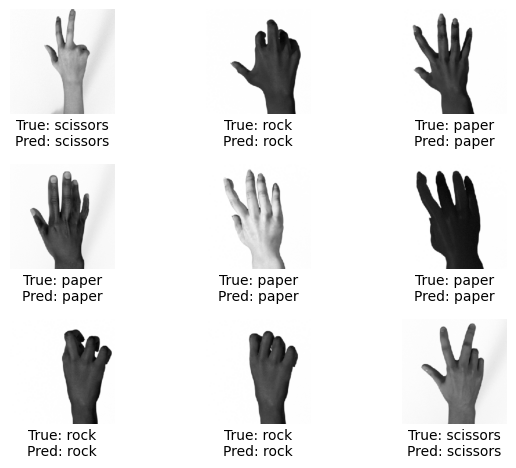

In [15]:
prediction = model.predict(X_test)
pred = np.argmax(prediction, axis=1)
true = np.argmax(Y_test, axis=1)

for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(X_test[i], cmap="gray")
    plt.axis(False)
    plt.text(0.5, -0.15, f"True: {classes[true[i]]}", ha="center", transform=plt.gca().transAxes)
    plt.text(0.5, -0.3, f"Pred: {classes[pred[i]]}", ha="center", transform=plt.gca().transAxes)

plt.tight_layout()
plt.show()

## Plotting

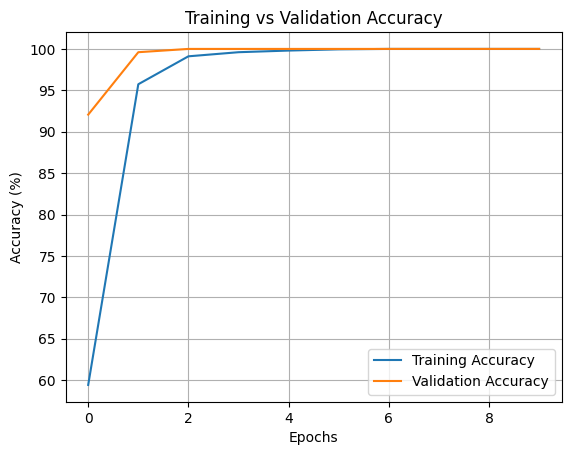

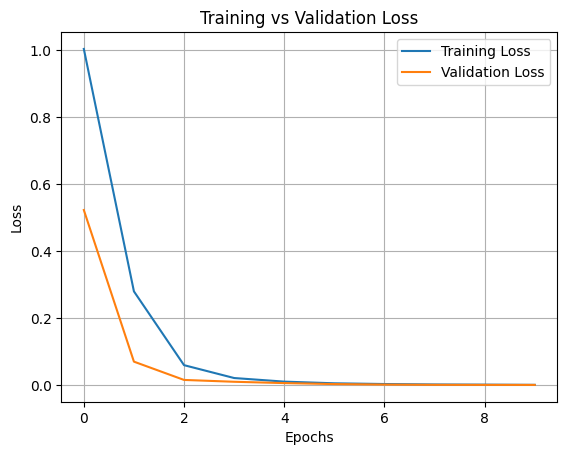

In [14]:
plt.title("Training vs Validation Accuracy")
plt.plot([x * 100 for x in history.history["accuracy"]], label="Training Accuracy")
plt.plot([x * 100 for x in history.history["val_accuracy"]], label="Validation Accuracy")
plt.grid(True)
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.show()

plt.title("Training vs Validation Loss")
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.grid(True)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()